# 1. Exploração Inicial:
Nesta etapa, será realizada a exploração estrutural da base de dados de vendas, com o objetivo de conhecer sua dimensão, identificar os tipos de dados de cada variável e verificar possíveis problemas iniciais de qualidade.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Lendo a base de dados e criando um dataframe com os dados brutos.
df_vendas = pd.read_csv('vendas.csv',sep=';')

#Exploração estrutural do DataFrame
df_vendas.info()



<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_item_venda      50000 non-null  int64  
 1   id_pedido          50000 non-null  int64  
 2   data_venda         50000 non-null  str    
 3   nome_produto       50000 non-null  str    
 4   categoria_produto  50000 non-null  str    
 5   quantidade         50000 non-null  int64  
 6   preco_unitario     50000 non-null  float64
 7   desconto           50000 non-null  float64
 8   valor_total        50000 non-null  float64
 9   nome_cliente       50000 non-null  str    
 10  cidade_cliente     49850 non-null  str    
 11  estado_cliente     50000 non-null  str    
 12  nome_vendedor      50000 non-null  str    
 13  forma_pagamento    50000 non-null  str    
 14  status_venda       50000 non-null  str    
dtypes: float64(3), int64(3), str(9)
memory usage: 5.7 MB


### Análise estrutural

A base de dados apresenta 50.000 registros distribuídos em 15 colunas, contendo informações sobre vendas, produtos, clientes e vendedores.

Durante a exploração, foi identificado que a coluna data_venda está armazenada como texto (str), sendo necessária sua conversão para o formato de data posteriormente.

Também foram identificados 150 valores ausentes na coluna cidade_cliente. As demais colunas apresentam preenchimento completo.

# 2. Tratamento dos Dados

Nesta etapa, serão identificados e tratados valores ausentes, registros duplicados e possíveis inconsistências na base de dados.

In [2]:
#Verificando a quantidade de valores ausentes em cada coluna.
df_vendas.isna().sum()

id_item_venda          0
id_pedido              0
data_venda             0
nome_produto           0
categoria_produto      0
quantidade             0
preco_unitario         0
desconto               0
valor_total            0
nome_cliente           0
cidade_cliente       150
estado_cliente         0
nome_vendedor          0
forma_pagamento        0
status_venda           0
dtype: int64

In [3]:
#Substituindo os valores ausentes da coluna cidade_cliente por "Não informado".
df_vendas['cidade_cliente'] = df_vendas['cidade_cliente'].fillna('Não informado')

#Confirmando substituição de dados ausentes na coluna cidade_cliente.
df_vendas.isna().sum()

id_item_venda        0
id_pedido            0
data_venda           0
nome_produto         0
categoria_produto    0
quantidade           0
preco_unitario       0
desconto             0
valor_total          0
nome_cliente         0
cidade_cliente       0
estado_cliente       0
nome_vendedor        0
forma_pagamento      0
status_venda         0
dtype: int64

In [4]:
#Verificando a quantidade de registros duplicados na base de vendas.
df_vendas.duplicated().sum()

np.int64(150)

In [5]:
#Removendo os registros duplicados da base de vendas.
df_vendas = df_vendas.drop_duplicates()

#Confirmando a ausência de registros duplicados após o tratamento.
df_vendas.duplicated().sum()

np.int64(0)

In [6]:
#Convertendo a coluna data_venda para datetime e mantendo datas inválidas como NaT.
df_vendas['data_venda'] = pd.to_datetime(
    df_vendas['data_venda'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce')

#Verificando a quantidade de datas inválidas após a conversão.
df_vendas['data_venda'].isna().sum()

np.int64(149)

In [7]:
#Identificando possíveis erros de digitação na coluna status_venda.
df_vendas['status_venda'].value_counts()

status_venda
Concluído    42430
Cancelado     3913
Pendente      1942
Devolvido     1565
Name: count, dtype: int64

In [8]:
#Identificando possíveis erros de digitação na coluna forma_pagamento.
df_vendas['forma_pagamento'].value_counts()

forma_pagamento
Cartão de Crédito    12714
Boleto               12533
PIX                  12521
Cartão de Débito     12082
Name: count, dtype: int64

In [9]:
#Identificando possíveis erros de digitação na categoria_produto.
df_vendas['categoria_produto'].value_counts()

categoria_produto
Informática    19847
Eletrônicos    13297
Acessórios      9918
Áudio           6679
Informatica       62
Eletronicos       47
Name: count, dtype: int64

In [10]:
#Corrigindo inconsistências de escrita na coluna categoria_produto.
df_vendas['categoria_produto'] = df_vendas['categoria_produto'].replace('Informatica','Informática')

df_vendas['categoria_produto'] = df_vendas['categoria_produto'].replace('Eletronicos','Eletrônicos')

#Verificando inconsistências das categorias após as correções.
df_vendas['categoria_produto'].value_counts()

categoria_produto
Informática    19909
Eletrônicos    13344
Acessórios      9918
Áudio           6679
Name: count, dtype: int64

In [11]:
#Verificando inconsistências dos nomes dos produtos.
df_vendas['nome_produto'].value_counts()

nome_produto
Teclado Mecânico RGB        3404
Tablet 10"                  3396
Smart TV 55" 4K             3358
Monitor 24" Full HD         3356
Monitor 27" 4K              3354
Caixa de Som Portátil       3342
Fone de Ouvido Bluetooth    3337
Smartwatch Fit Z            3320
Carregador Super Rápido     3316
Mouse Gamer 10k DPI         3311
Smartphone Básico Y         3310
Notebook Ultra Pro          3282
Cabo USB-C 2m               3282
Smartphone Premium X        3280
Notebook Estudante          3202
Name: count, dtype: int64

In [12]:
#Verificando inconsistências dos estados dos clientes.
df_vendas['estado_cliente'].value_counts()

estado_cliente
PR    5138
DF    5102
SC    5032
GO    4993
BA    4970
MG    4966
RJ    4954
SP    4913
PE    4893
RS    4889
Name: count, dtype: int64

In [13]:
# Verificando inconsistências das cidades dos clientes.
df_vendas['cidade_cliente'].value_counts()

cidade_cliente
Brasília                5089
Aparecida de Goiânia    1697
Blumenau                1690
Vitória da Conquista    1690
Anápolis                1689
Recife                  1679
Olinda                  1668
Florianópolis           1668
Joinville               1661
Salvador                1656
Feira de Santana        1608
Goiânia                 1591
Caruaru                 1531
Cascavel                1324
Contagem                1302
Londrina                1298
Rio de Janeiro          1295
Caxias do Sul           1270
Maringá                 1267
Uberlândia              1250
Pelotas                 1235
Curitiba                1230
Juiz de Fora            1226
Niterói                 1225
Petrópolis              1220
Duque de Caxias         1197
Porto Alegre            1191
Santa Maria             1177
Belo Horizonte          1175
Campinas                1066
Ribeirão Preto          1041
São Paulo               1009
Osasco                   934
Santos                   851

In [14]:
# Verificando inconsistências dos nomes dos vendedores.
df_vendas['nome_vendedor'].value_counts()

nome_vendedor
Julia Martins     3473
Carlos Eduardo    3468
Kauan Vieira      3412
Marcos Paulo      3409
Fernanda Alves    3407
Otávio Borges     3377
Ana Silva         3342
Gabriel Gomes     3316
Larissa Mendes    3295
Diana Souza       3284
Eduardo Lima      3228
Bruno Costa       3228
Igor Santos       3212
Helena Rocha      3206
Natália Pires     3193
Name: count, dtype: int64

In [15]:
#Contabilizando registros com quantidade negativa.
(df_vendas['quantidade'] < 0).sum()

np.int64(62)

In [16]:
#Visualizando os registros com quantidade negativa, seus status e valores financeiros.
df_vendas.loc[
    df_vendas['quantidade'] < 0,
    ['id_item_venda', 'nome_produto', 'quantidade',
     'preco_unitario', 'desconto', 'valor_total', 'status_venda']]

,id_item_venda,nome_produto,quantidade,preco_unitario,desconto,valor_total,status_venda
314,315,Cabo USB-C 2m,-3,45.0,11.43,123.57,Concluído
672,673,"Monitor 27"" 4K",-3,2100.0,315.23,5984.77,Concluído
879,880,"Tablet 10""",-1,1900.0,139.44,1760.56,Concluído
1164,1165,Smartphone Premium X,-3,4500.0,0.00,13500.00,Concluído
1822,1823,Notebook Estudante,-1,2800.0,462.90,2337.10,Concluído
...,...,...,...,...,...,...,...
44952,44953,Smartphone Premium X,-1,4500.0,0.00,4500.00,Concluído
47578,47579,Teclado Mecânico RGB,-2,550.0,0.00,1100.00,Cancelado
48787,48788,Notebook Ultra Pro,-1,8500.0,0.00,8500.00,Concluído
49184,49185,Carregador Super Rápido,-1,120.0,0.00,120.00,Cancelado


In [17]:
#Contabilizando os status das vendas que possuem quantidade negativa.
df_vendas.loc[df_vendas['quantidade'] < 0, 'status_venda'].value_counts()


status_venda
Concluído    52
Cancelado     8
Devolvido     1
Pendente      1
Name: count, dtype: int64

In [18]:
#Contabilizando registros com preço unitário igual ou menor que zero.
(df_vendas['preco_unitario'] <= 0).sum()

np.int64(0)

In [19]:
#Contabilizando registros com descontos negativos.
(df_vendas['desconto'] < 0).sum()

np.int64(0)

In [20]:
#Identificando descontos superiores ao valor bruto dos itens.
(df_vendas['desconto'] > (df_vendas['quantidade'] * df_vendas['preco_unitario'])).sum()

np.int64(149)

In [21]:
#Identificando descontos superiores ao valor bruto em itens com quantidade positiva.
((df_vendas['quantidade'] > 0) &
 (df_vendas['desconto'] > df_vendas['quantidade'] * df_vendas['preco_unitario'])).sum()

np.int64(87)

In [22]:
#Verificando registros em que o valor_total diverge do cálculo esperado.
calculo_esperado = (df_vendas['preco_unitario'] * df_vendas['quantidade']) - df_vendas['desconto']

(~np.isclose(df_vendas['valor_total'], calculo_esperado)).sum()

np.int64(62)

In [23]:
#Verificando divergências no valor_total em registros com quantidade positiva.
((~np.isclose(df_vendas['valor_total'], calculo_esperado)) &
 (df_vendas['quantidade'] > 0)).sum()

np.int64(0)

### Análise de valores ausentes
Foi identificado um total de 150 valores ausentes na coluna cidade_cliente, representando 0,3% dos registros da base de dados.
As demais colunas não apresentaram valores ausentes.

### Tratamento de valores ausentes
Para preservar os demais dados das vendas, os 150 valores ausentes da coluna cidade_cliente foram substituídos por "Não informado".

### Tratamento de registros duplicados

Foram identificados 150 registros duplicados na base de dados. Esses registros foram removidos utilizando o método drop_duplicates() do Pandas.
Após a remoção, uma nova verificação confirmou que não existem mais registros duplicados.

### Tratamento de datas inválidas

Foram identificados 149 registros com datas inválidas. Durante a conversão da coluna data_venda para o tipo datetime, esses valores foram convertidos para NaT.
Os registros foram preservados para evitar a perda de informações comerciais. Entretanto, serão desconsiderados nas análises que dependam de datas válidas.

### Verificação de inconsistências categóricas

Foram identificadas inconsistências de escrita na coluna `categoria_produto`, relacionadas à ausência de acentuação em alguns registros.

### Correção das inconsistências

As seguintes correções foram realizadas:

- `Informatica` foi substituído por `Informática`.
- `Eletronicos` foi substituído por `Eletrônicos`.

Após as correções, uma nova verificação confirmou a padronização dos nomes das categorias.

As demais colunas categóricas verificadas não apresentaram inconsistências aparentes.

### Verificação de inconsistências numéricas

Durante a análise da coluna `quantidade`, foram identificados 62 registros com valores negativos.

Esses registros apresentaram diferentes status de venda, incluindo vendas concluídas, canceladas, devolvidas e pendentes.

Também foi observado que os valores financeiros desses registros permanecem positivos, mesmo quando a quantidade é negativa.

Como não há informações suficientes para determinar a origem dessas inconsistências, os registros foram preservados, sem alterações.

### Verificação de inconsistências financeiras

Foram identificados 87 registros com quantidade positiva em que o desconto supera o valor bruto dos itens.

Também foram encontradas 62 divergências no cálculo da coluna `valor_total`, todas associadas a registros com quantidade negativa.

Como não há informações suficientes para determinar os valores corretos, os registros foram preservados, sem alterações.

# 3. Análise do Faturamento

Nesta etapa, será analisado o desempenho financeiro das vendas, considerando o faturamento bruto e líquido da empresa, com base nos registros de vendas concluídas.

In [24]:
#Contabilizando a quantidade de vendas por status.
df_vendas['status_venda'].value_counts()

status_venda
Concluído    42430
Cancelado     3913
Pendente      1942
Devolvido     1565
Name: count, dtype: int64

In [25]:
#Filtrando apenas os registros de vendas concluídas.
df_vendas_concluidas = df_vendas[
    df_vendas['status_venda'] == 'Concluído']

#Calculando o faturamento bruto das vendas concluídas.
faturamento_bruto = (
    df_vendas_concluidas['preco_unitario'] *
    df_vendas_concluidas['quantidade']
).sum()

faturamento_bruto

np.float64(117583055.19999999)

In [26]:
#Calculando o faturamento líquido das vendas concluídas.
faturamento_liquido = (
    df_vendas_concluidas['valor_total']
).sum()

faturamento_liquido

np.float64(110552144.81)

In [32]:
#Calculando o percentual de descontos sobre o faturamento bruto.
percentual_descontos = (
    (faturamento_bruto - faturamento_liquido) /
    faturamento_bruto
) * 100

percentual_descontos


np.float64(5.979526878291207)

### Análise do faturamento

O faturamento bruto das vendas concluídas foi de R$ 117.583.055,20.

Após considerar os descontos concedidos, o faturamento líquido foi de R$ 110.552.144,81.

Os descontos representaram aproximadamente 5,98% do faturamento bruto.

# 4. Análise do Volume de Vendas

Nesta etapa, serão identificados os produtos com maior volume de unidades vendidas, permitindo avaliar quais itens apresentam maior demanda.

In [28]:
#Agrupando os produtos e somando suas quantidades vendidas.
vendas_por_produto = (
    df_vendas_concluidas.groupby('nome_produto')['quantidade']
    .sum()
    .sort_values(ascending=False)
)

vendas_por_produto.head(10)

nome_produto
Teclado Mecânico RGB        4392
Monitor 27" 4K              4330
Smartphone Premium X        4276
Mouse Gamer 10k DPI         4274
Smartphone Básico Y         4271
Notebook Estudante          4230
Caixa de Som Portátil       4229
Smart TV 55" 4K             4184
Fone de Ouvido Bluetooth    4178
Notebook Ultra Pro          4169
Name: quantidade, dtype: int64

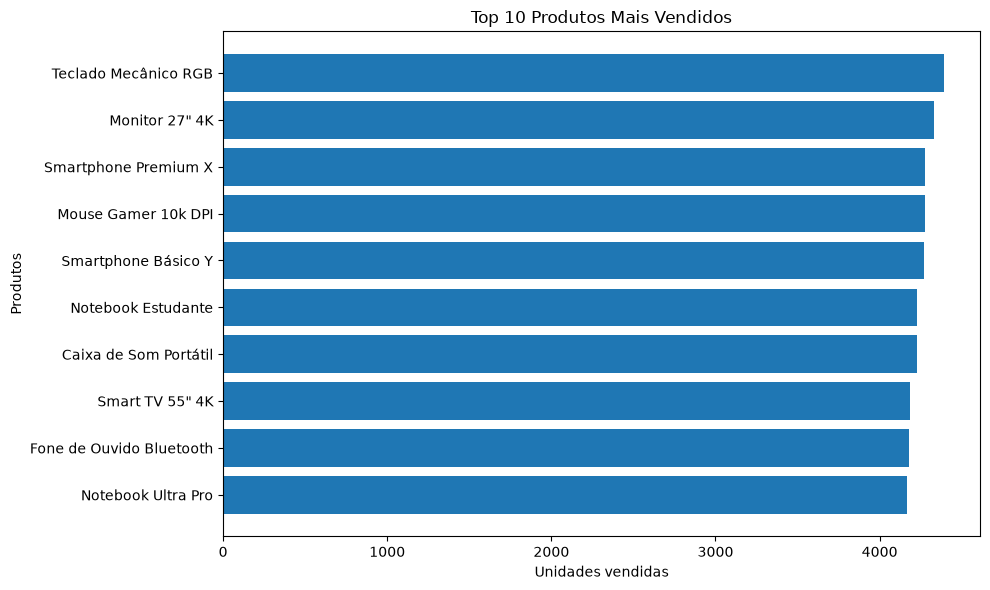

In [35]:
#Selecionando os 10 produtos mais vendidos.
top_10_produtos = vendas_por_produto.head(10).sort_values()

#Criando o gráfico.
plt.figure(figsize=(10, 6))
plt.barh(top_10_produtos.index, top_10_produtos.values)

#Configurando o gráfico.
plt.title('Top 10 Produtos Mais Vendidos')
plt.xlabel('Unidades vendidas')
plt.ylabel('Produtos')

plt.tight_layout()
plt.show()

### Análise dos produtos mais vendidos

O Teclado Mecânico RGB apresentou o maior volume de vendas, com 4.392 unidades comercializadas. Já o Notebook Ultra Pro ocupou a décima posição, com 4.169 unidades.

Os resultados demonstram uma distribuição relativamente equilibrada entre os dez produtos, sem diferenças expressivas no volume de vendas entre as primeiras e últimas posições do ranking.